In [24]:
import pandas as pd
import numpy as np
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

# Load dataset with encoding
df = pd.read_csv("zomato.csv", encoding="latin1")


Current working directory:
/Users/mahithakalinathabotla

Files in this directory:
['.config', 'Music', 'file5.json', '.condarc', '.DS_Store', 'file4.json', '.CFUserTextEncoding', '.xonshrc', 'anaconda_projects', 'OneDrive - University at Albany - SUNY', 'Untitled.ipynb', 'file3.json', '.zshrc', '.local', 'Pictures', '.zprofile', '.zsh_history', '.ipython', 'zomato.csv', 'Desktop', 'Library', '.matplotlib', '.lesshst', 'file2.json', 'my_first_notebook', 'file1.json', 'Public', '.tcshrc', '.virtual_documents', '.anaconda', 'Movies', 'Applications', '.Trash', '.ipynb_checkpoints', '.jupyter', 'Documents', '.mysql_history', '.vscode', '.bash_profile', 'Country-Code.xlsx', 'data', 'Downloads', '.continuum', 'School', '.zsh_sessions', '.conda']


In [26]:
df.info()
df.shape
df.columns
df.describe()
df.isnull().sum()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [28]:
df['City'].value_counts().head(10)

df['Cuisines'].value_counts().head(10)

df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).head(10)

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Tagaytay City       4.500000
Secunderabad        4.500000
Name: Aggregate rating, dtype: float64

In [30]:
#Top Cities by number of restaurants 
df['City'].value_counts().head(10)

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Amritsar          21
Ahmedabad         21
Lucknow           21
Guwahati          21
Name: count, dtype: int64

In [32]:
#Most popular Cuisines 
df['Cuisines'].value_counts().head(10)

Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64

In [34]:
#Online delivery vs Rating 
df.groupby('Has Online delivery')['Aggregate rating'].mean()

Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64

In [36]:
#Table booking vs Rating
df.groupby('Has Table booking')['Aggregate rating'].mean()

Has Table booking
No     2.559359
Yes    3.441969
Name: Aggregate rating, dtype: float64

In [38]:
#Price Range vs Rating 
df.groupby('Price range')['Aggregate rating'].mean()

Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64

In [42]:
#Restaurants with most votes
df.sort_values(by='Votes', ascending=False).head(10)[
    ['Restaurant Name','City','Votes']
]

,Restaurant Name,City,Votes
728,Toit,Bangalore,10934
735,Truffles,Bangalore,9667
3994,Hauz Khas Social,New Delhi,7931
2412,Peter Cat,Kolkata,7574
739,AB's - Absolute Barbecues,Bangalore,6907
2414,Barbeque Nation,Kolkata,5966
743,Big Brewsky,Bangalore,5705
2307,AB's - Absolute Barbecues,Hyderabad,5434
736,The Black Pearl,Bangalore,5385
2411,BarBQ,Kolkata,5288


In [44]:
#Top Rated restaurants
df.sort_values(by='Aggregate rating', ascending=False).head(10)[
    ['Restaurant Name','City','Aggregate rating']
]

,Restaurant Name,City,Aggregate rating
1381,Caterspoint,Gurgaon,4.9
589,AB's Absolute Barbecues,Dubai,4.9
374,McGuire's Irish Pub & Brewery,Pensacola,4.9
9303,Miann,Auckland,4.9
9299,Milse,Auckland,4.9
9296,Talaga Sampireun,Tangerang,4.9
50,Garota de Ipanema,Rio de Janeiro,4.9
9291,Talaga Sampireun,Jakarta,4.9
48,Braseiro da Gíçvea,Rio de Janeiro,4.9
428,Mama's Fish House,Rest of Hawaii,4.9


In [46]:
#Average Rating per City
df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).head(10)

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Tagaytay City       4.500000
Secunderabad        4.500000
Name: Aggregate rating, dtype: float64

In [50]:
#Correlation Analysis
df[['Votes','Average Cost for two','Aggregate rating']].corr()

,Votes,Average Cost for two,Aggregate rating
Votes,1.000000,0.067783,0.313691
Average Cost for two,0.067783,1.000000,0.051792
Aggregate rating,0.313691,0.051792,1.000000


In [52]:
#Top Counties with Most Restaurants 
df['Country Code'].value_counts()

Country Code
1      8652
216     434
215      80
30       60
214      60
189      60
148      40
208      34
14       24
162      22
94       21
184      20
166      20
191      20
37        4
Name: count, dtype: int64

In [54]:
#Restaurants with High Cost but low ratings
df[(df['Average Cost for two'] > 2000) & (df['Aggregate rating'] < 3)][
    ['Restaurant Name','City','Average Cost for two','Aggregate rating']
].head()

,Restaurant Name,City,Average Cost for two,Aggregate rating
1122,9 Mars Lounge,Ghaziabad,2500,2.5
1189,Lattitude - Skycity Hotel,Gurgaon,2500,2.9
1207,Courtyard Grill - Courtyard by Marriott,Gurgaon,2500,0.0
1461,Orchid - Fortune Select Global,Gurgaon,2500,2.6
1513,Coffee to Cocktail Bar - Hyatt Place,Gurgaon,2100,0.0


In [56]:
#Best Cuisine based on ratings
df.groupby('Cuisines')['Aggregate rating'].mean().sort_values(ascending=False).head(10)

Cuisines
Italian, Deli               4.9
Hawaiian, Seafood           4.9
American, Sandwich, Tea     4.9
Continental, Indian         4.9
European, Asian, Indian     4.9
European, Contemporary      4.9
European, German            4.9
BBQ, Breakfast, Southern    4.9
American, Coffee and Tea    4.9
Sunda, Indonesian           4.9
Name: Aggregate rating, dtype: float64

In [58]:
#City with highest votes
df.groupby('City')['Votes'].sum().sort_values(ascending=False).head(10)

City
New Delhi    628340
Gurgaon      132160
Noida         73488
Bangalore     56115
Kolkata       44593
Mumbai        29697
Chennai       27695
Tampa Bay     27407
Hyderabad     24135
Orlando       23989
Name: Votes, dtype: int64

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

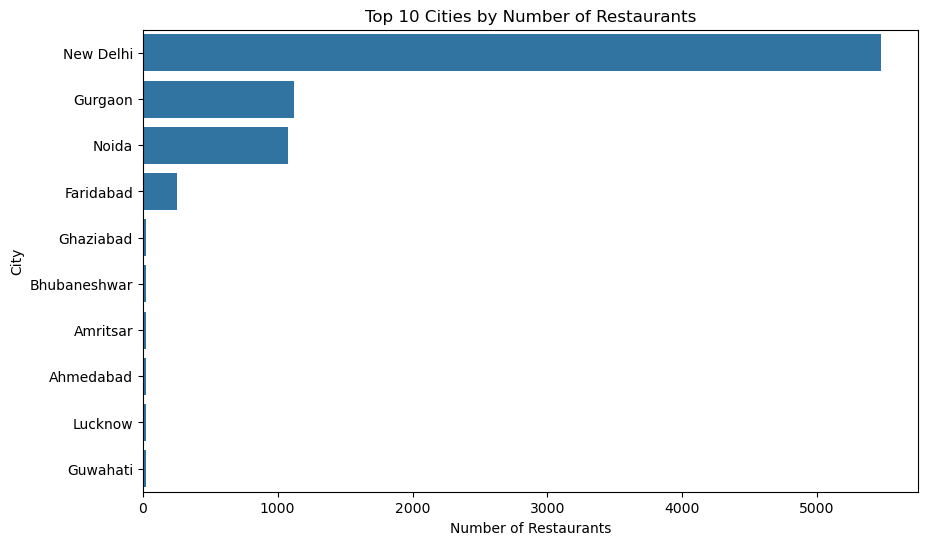

In [64]:
#top cities by number of restaurants 
top_cities = df['City'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_cities.values, y=top_cities.index)

plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.show()

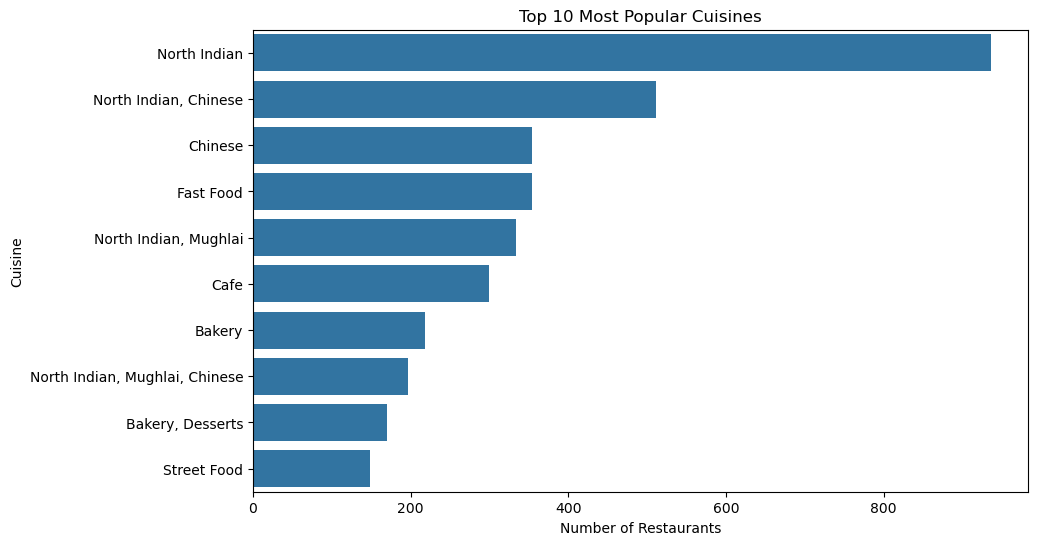

In [66]:
#most popular cuisines 
top_cuisines = df['Cuisines'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index)

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")

plt.show()

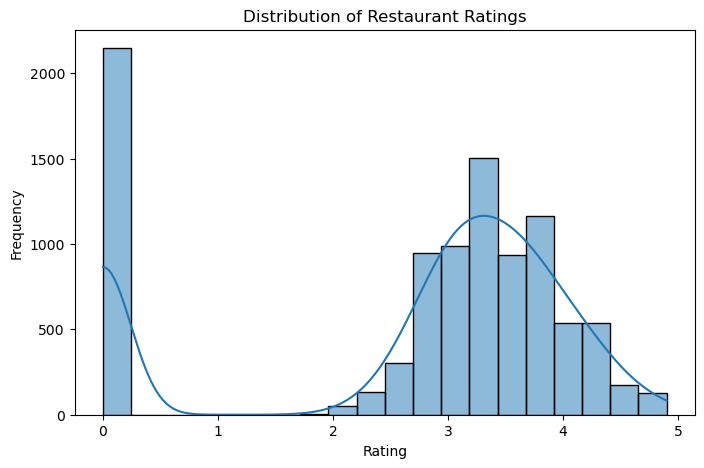

In [68]:
#rating distribution 
plt.figure(figsize=(8,5))

sns.histplot(df['Aggregate rating'], bins=20, kde=True)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")

plt.show()

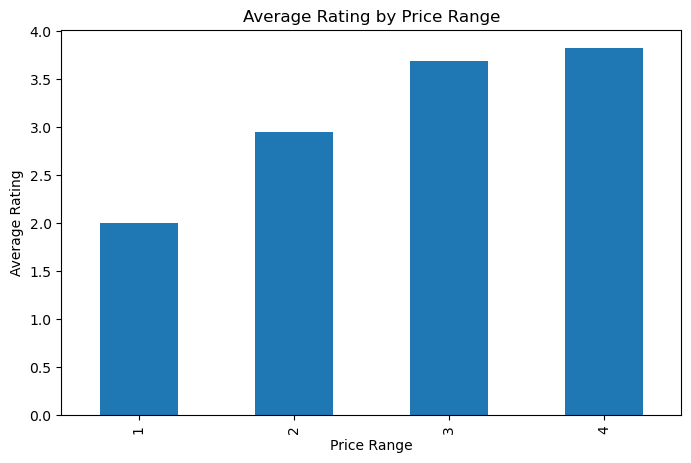

In [70]:
#price range vs average rating 
price_rating = df.groupby('Price range')['Aggregate rating'].mean()

plt.figure(figsize=(8,5))
price_rating.plot(kind='bar')

plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")

plt.show()

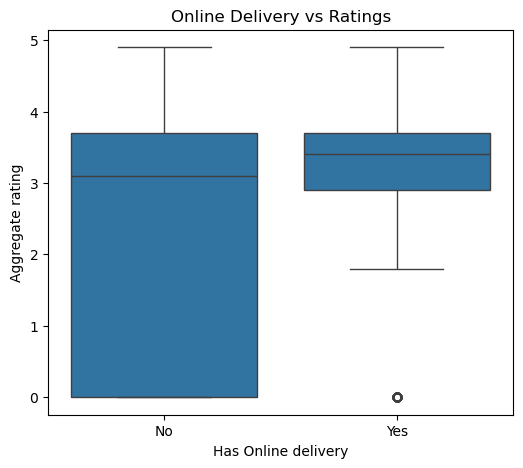

In [72]:
#online delivery vs ratings
plt.figure(figsize=(6,5))

sns.boxplot(x='Has Online delivery', y='Aggregate rating', data=df)

plt.title("Online Delivery vs Ratings")

plt.show()

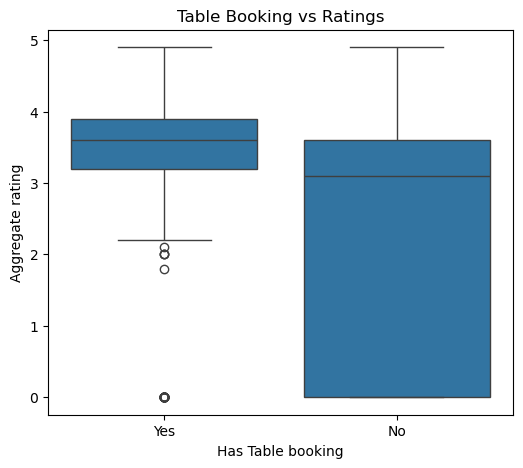

In [74]:
#table booking vs ratings
plt.figure(figsize=(6,5))

sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df)

plt.title("Table Booking vs Ratings")

plt.show()

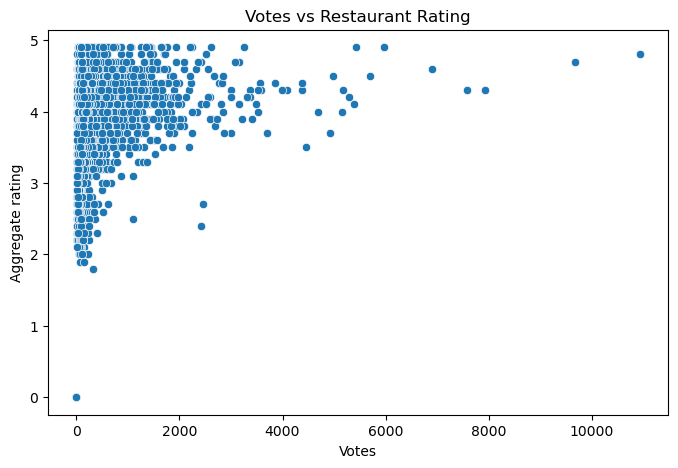

In [76]:
#votes vs rating (customer engagement)
plt.figure(figsize=(8,5))

sns.scatterplot(x='Votes', y='Aggregate rating', data=df)

plt.title("Votes vs Restaurant Rating")

plt.show()

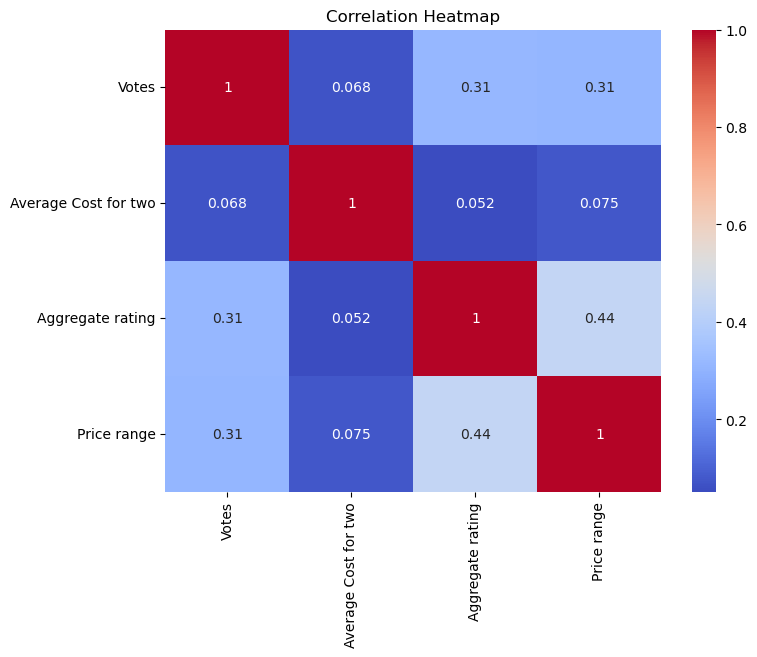

In [78]:
#correlation heatmap
plt.figure(figsize=(8,6))

sns.heatmap(df[['Votes','Average Cost for two','Aggregate rating','Price range']].corr(),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

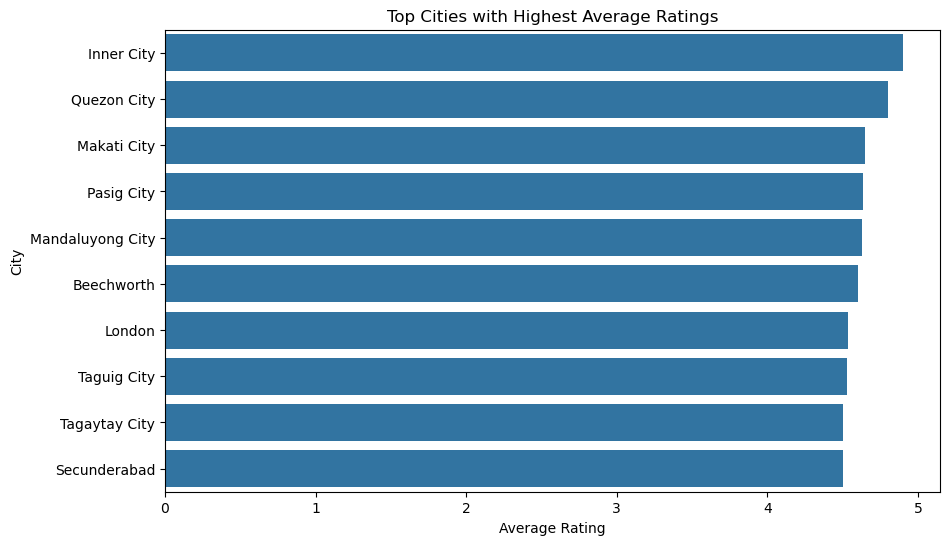

In [90]:
#top rated cities 
top_rated_cities = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))

sns.barplot(x=top_rated_cities.values, y=top_rated_cities.index)

plt.title("Top Cities with Highest Average Ratings")
plt.xlabel("Average Rating")
plt.ylabel("City")

plt.show()

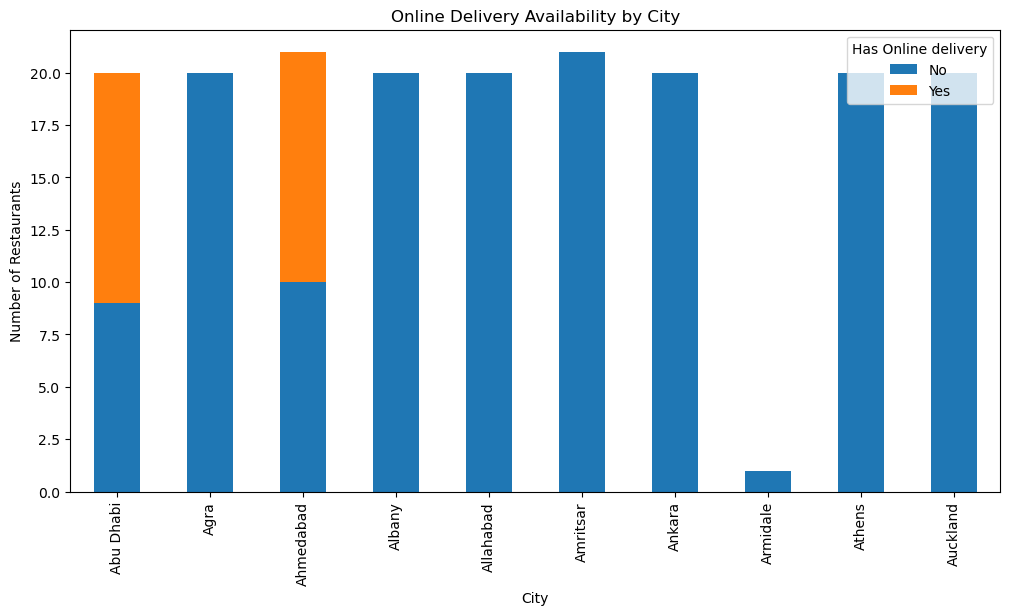

In [88]:
#restaurants offering online delivery by city 
delivery_city = df.groupby('City')['Has Online delivery'].value_counts().unstack()

delivery_city.head(10).plot(kind='bar', stacked=True, figsize=(12,6))

plt.title("Online Delivery Availability by City")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")

plt.show()

In [8]:
import pandas as pd

df = pd.read_csv(
    "/Users/mahithakalinathabotla/zomato.csv",
    encoding="latin1"
)

In [10]:
print("Shape:", df.shape)

display(df.head())

df.info()

display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nUnique values:")
print(df.nunique())

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
count,9.551000e+03,9551,9551.000000,9551,9551,9551,9551,9551.000000,9551.000000,9542,...,9551,9551,9551,9551,9551,9551.000000,9551.000000,9551,9551,9551.000000
unique,NaN,7446,NaN,141,8918,1208,1265,NaN,NaN,1825,...,12,2,2,2,1,NaN,NaN,6,6,NaN
top,NaN,Cafe Coffee Day,NaN,New Delhi,"Dilli Haat, INA, New Delhi",Connaught Place,"Connaught Place, New Delhi",NaN,NaN,North Indian,...,Indian Rupees(Rs.),No,No,No,No,NaN,NaN,Orange,Average,NaN
freq,NaN,83,NaN,5473,11,122,122,NaN,NaN,936,...,8652,8393,7100,9517,9551,NaN,NaN,3737,3737,NaN
mean,9.051128e+06,NaN,18.365616,NaN,NaN,NaN,NaN,64.126574,25.854381,NaN,...,NaN,NaN,NaN,NaN,NaN,1.804837,2.666370,NaN,NaN,156.909748
std,8.791521e+06,NaN,56.750546,NaN,NaN,NaN,NaN,41.467058,11.007935,NaN,...,NaN,NaN,NaN,NaN,NaN,0.905609,1.516378,NaN,NaN,430.169145
min,5.300000e+01,NaN,1.000000,NaN,NaN,NaN,NaN,-157.948486,-41.330428,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,NaN,0.000000
25%,3.019625e+05,NaN,1.000000,NaN,NaN,NaN,NaN,77.081343,28.478713,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,2.500000,NaN,NaN,5.000000
50%,6.004089e+06,NaN,1.000000,NaN,NaN,NaN,NaN,77.191964,28.570469,NaN,...,NaN,NaN,NaN,NaN,NaN,2.000000,3.200000,NaN,NaN,31.000000
75%,1.835229e+07,NaN,1.000000,NaN,NaN,NaN,NaN,77.282006,28.642758,NaN,...,NaN,NaN,NaN,NaN,NaN,2.000000,3.700000,NaN,NaN,131.000000



Missing values:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Duplicate rows:
0

Unique values:
Restaurant ID           9551
Restaurant Name         7446
Country Code              15
City                     141
Address                 8918
Locality                1208
Locality Verbose        1265
Longitude               8120
Latitude                8677
Cuisines                1825
Average Cost for two     140
Currency                  12
Has Table booking          2
Has Online d

In [12]:
# Basic dataset overview

print("Rows and columns:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print(col)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())

Rows and columns: (9551, 21)

Column names:
Restaurant ID
Restaurant Name
Country Code
City
Address
Locality
Locality Verbose
Longitude
Latitude
Cuisines
Average Cost for two
Currency
Has Table booking
Has Online delivery
Is delivering now
Switch to order menu
Price range
Aggregate rating
Rating color
Rating text
Votes

Data types:
Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             object
Rating text              object
Votes                     

In [14]:
# Numerical columns
print("Numerical columns:")
display(df.select_dtypes(include="number").describe().T)

Numerical columns:


,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9.051128e+06,8.791521e+06,53.000000,301962.500000,6.004089e+06,1.835229e+07,1.850065e+07
Country Code,9551.0,1.836562e+01,5.675055e+01,1.000000,1.000000,1.000000e+00,1.000000e+00,2.160000e+02
Longitude,9551.0,6.412657e+01,4.146706e+01,-157.948486,77.081343,7.719196e+01,7.728201e+01,1.748321e+02
Latitude,9551.0,2.585438e+01,1.100794e+01,-41.330428,28.478713,2.857047e+01,2.864276e+01,5.597698e+01
Average Cost for two,9551.0,1.199211e+03,1.612118e+04,0.000000,250.000000,4.000000e+02,7.000000e+02,8.000000e+05
Price range,9551.0,1.804837e+00,9.056088e-01,1.000000,1.000000,2.000000e+00,2.000000e+00,4.000000e+00
Aggregate rating,9551.0,2.666370e+00,1.516378e+00,0.000000,2.500000,3.200000e+00,3.700000e+00,4.900000e+00
Votes,9551.0,1.569097e+02,4.301691e+02,0.000000,5.000000,3.100000e+01,1.310000e+02,1.093400e+04


In [16]:
# Categorical columns
print("Categorical columns:")
display(df.select_dtypes(include="object").describe().T)

Categorical columns:


,count,unique,top,freq
Restaurant Name,9551,7446,Cafe Coffee Day,83
City,9551,141,New Delhi,5473
Address,9551,8918,"Dilli Haat, INA, New Delhi",11
Locality,9551,1208,Connaught Place,122
Locality Verbose,9551,1265,"Connaught Place, New Delhi",122
Cuisines,9542,1825,North Indian,936
Currency,9551,12,Indian Rupees(Rs.),8652
Has Table booking,9551,2,No,8393
Has Online delivery,9551,2,No,7100
Is delivering now,9551,2,No,9517


In [18]:
print("Missing values:")
missing = df.isnull().sum().sort_values(ascending=False)

display(missing[missing > 0])

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:


Cuisines    9
dtype: int64


Duplicate rows:
0


In [20]:
print("Columns with only one unique value:")

unique_counts = df.nunique().sort_values()

display(unique_counts[unique_counts == 1])

Columns with only one unique value:


Switch to order menu    1
dtype: int64

In [22]:
print("All columns:")
print(df.columns.tolist())

All columns:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [24]:
import pandas as pd
import numpy as np
import os

In [26]:
df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

0

In [28]:
# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (9551, 21)


In [30]:
# Remove constant column
df_clean = df_clean.drop(columns=["Switch to order menu"])

print("Shape after removing constant column:", df_clean.shape)

Shape after removing constant column: (9551, 20)


In [32]:
df_clean["Cuisines"] = df_clean["Cuisines"].fillna("Unknown")

print("Missing cuisines:", df_clean["Cuisines"].isnull().sum())

Missing cuisines: 0


In [34]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [36]:
df_clean["Primary Cuisine"] = (
    df_clean["Cuisines"]
    .str.split(",")
    .str[0]
    .str.strip()
)

df_clean[["Cuisines", "Primary Cuisine"]].head(10)

,Cuisines,Primary Cuisine
0,"French, Japanese, Desserts",French
1,Japanese,Japanese
2,"Seafood, Asian, Filipino, Indian",Seafood
3,"Japanese, Sushi",Japanese
4,"Japanese, Korean",Japanese
5,Chinese,Chinese
6,"Asian, European",Asian
7,"Seafood, Filipino, Asian, European",Seafood
8,"European, Asian, Indian",European
9,Filipino,Filipino


In [38]:
df_clean.to_csv("zomato_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Final shape:", df_clean.shape)

Cleaned dataset saved successfully.
Final shape: (9551, 21)


In [40]:
# Create useful features for analysis and modeling

# Binary service indicators
df_clean["Online Delivery Flag"] = (
    df_clean["Has Online delivery"].map({"Yes": 1, "No": 0})
)

df_clean["Table Booking Flag"] = (
    df_clean["Has Table booking"].map({"Yes": 1, "No": 0})
)

# Cost per person
df_clean["Estimated Cost per Person"] = (
    df_clean["Average Cost for two"] / 2
)

# Popularity category based on votes
df_clean["Popularity Category"] = pd.cut(
    df_clean["Votes"],
    bins=[-1, 50, 200, 500, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"]
)

display(
    df_clean[
        [
            "Restaurant Name",
            "Price range",
            "Average Cost for two",
            "Votes",
            "Aggregate rating",
            "Online Delivery Flag",
            "Table Booking Flag",
            "Estimated Cost per Person",
            "Popularity Category"
        ]
    ].head(10)
)

,Restaurant Name,Price range,Average Cost for two,Votes,Aggregate rating,Online Delivery Flag,Table Booking Flag,Estimated Cost per Person,Popularity Category
0,Le Petit Souffle,3,1100,314,4.8,0,1,550.0,High
1,Izakaya Kikufuji,3,1200,591,4.5,0,1,600.0,Very High
2,Heat - Edsa Shangri-La,4,4000,270,4.4,0,1,2000.0,High
3,Ooma,4,1500,365,4.9,0,0,750.0,High
4,Sambo Kojin,4,1500,229,4.8,0,1,750.0,High
5,Din Tai Fung,3,1000,336,4.4,0,0,500.0,High
6,Buffet 101,4,2000,520,4.0,0,1,1000.0,Very High
7,Vikings,4,2000,677,4.2,0,1,1000.0,Very High
8,Spiral - Sofitel Philippine Plaza Manila,4,6000,621,4.9,0,1,3000.0,Very High
9,Locavore,3,1100,532,4.8,0,1,550.0,Very High


In [42]:
print("New shape:", df_clean.shape)

print("\nMissing values:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nPopularity distribution:")
display(df_clean["Popularity Category"].value_counts())

New shape: (9551, 25)

Missing values:


Restaurant ID                0
Has Online delivery          0
Estimated Cost per Person    0
Table Booking Flag           0
Online Delivery Flag         0
Primary Cuisine              0
Votes                        0
Rating text                  0
Rating color                 0
Aggregate rating             0
dtype: int64


Popularity distribution:


Popularity Category
Low          5577
Moderate     2275
High          994
Very High     705
Name: count, dtype: int64

In [46]:
#Question 1: Which cities have the most restaurants?
city_restaurants = (
    df_clean.groupby("City")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Average_Votes=("Votes", "mean")
    )
    .sort_values("Restaurant_Count", ascending=False)
)

display(city_restaurants.head(15))

,Restaurant_Count,Average_Rating,Average_Votes
City,,,
New Delhi,5473,2.438845,114.807236
Gurgaon,1118,2.651431,118.211091
Noida,1080,2.036204,68.044444
Faridabad,251,1.866932,25.840637
Ghaziabad,25,2.852000,94.640000
Bhubaneshwar,21,3.980952,202.047619
Lucknow,21,4.195238,434.761905
Amritsar,21,3.685714,174.523810
Ahmedabad,21,4.161905,584.095238


In [48]:
#Question 2: Which cuisines are most common?
cuisine_analysis = (
    df_clean.groupby("Primary Cuisine")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Average_Votes=("Votes", "mean")
    )
    .sort_values("Restaurant_Count", ascending=False)
)

display(cuisine_analysis.head(15))

,Restaurant_Count,Average_Rating,Average_Votes
Primary Cuisine,,,
North Indian,2992,2.399699,119.212567
Chinese,855,2.325731,99.319298
Fast Food,672,2.351042,63.418155
Bakery,621,2.332206,67.645733
Cafe,617,3.232415,188.940032
American,278,3.555755,379.305755
South Indian,262,2.509160,131.194656
Mithai,246,1.834553,23.113821
Street Food,236,2.269915,73.656780


In [50]:
#Question 3: Does price range relate to ratings?
price_analysis = (
    df_clean.groupby("Price range")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Average_Votes=("Votes", "mean"),
        Average_Cost=("Average Cost for two", "mean")
    )
)

display(price_analysis)

,Restaurant_Count,Average_Rating,Average_Votes,Average_Cost
Price range,,,,
1,4444,1.999887,44.597435,275.182943
2,3113,2.941054,147.607131,596.826213
3,1408,3.683381,443.860795,5177.268466
4,586,3.817918,368.595563,1848.523891


In [52]:
#Question 4: Does online delivery relate to restaurant performance?
delivery_analysis = (
    df_clean.groupby("Has Online delivery")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Average_Votes=("Votes", "mean")
    )
)

display(delivery_analysis)

,Restaurant_Count,Average_Rating,Average_Votes
Has Online delivery,,,
No,7100,2.465296,138.131127
Yes,2451,3.248837,211.307222


In [54]:
#Question 5: Does table booking relate to performance?
booking_analysis = (
    df_clean.groupby("Has Table booking")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Average_Votes=("Votes", "mean")
    )
)

display(booking_analysis)

,Restaurant_Count,Average_Rating,Average_Votes
Has Table booking,,,
No,8393,2.559359,129.840105
Yes,1158,3.441969,353.106218


In [56]:
df_clean.to_csv("zomato_cleaned.csv", index=False)

print("Final dataset saved.")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Final dataset saved.
Rows: 9551
Columns: 25


In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

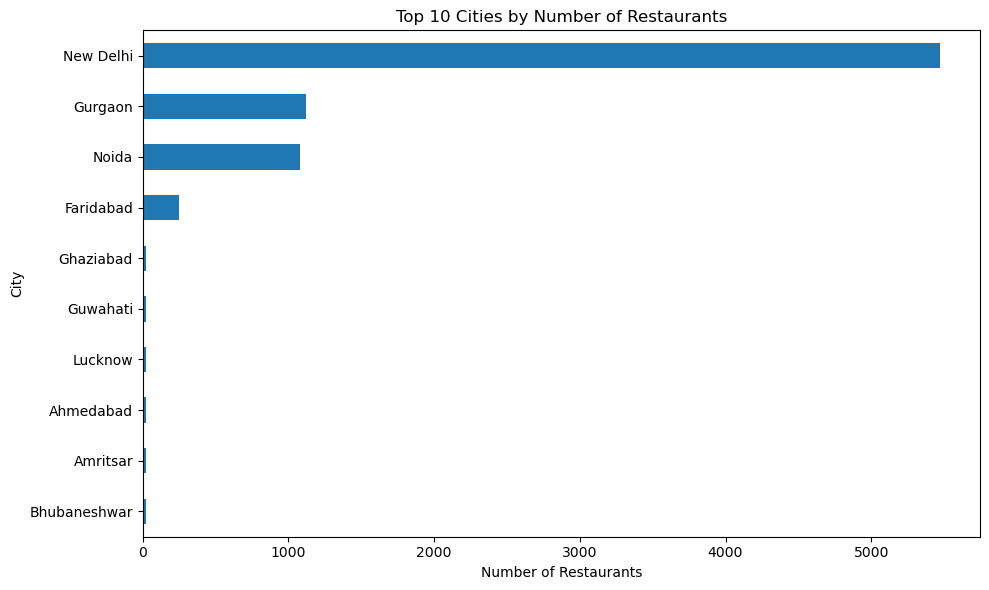

In [60]:
# Top 10 cities
top_cities = (
    df_clean["City"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
top_cities.sort_values().plot(kind="barh")
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.tight_layout()
plt.show()

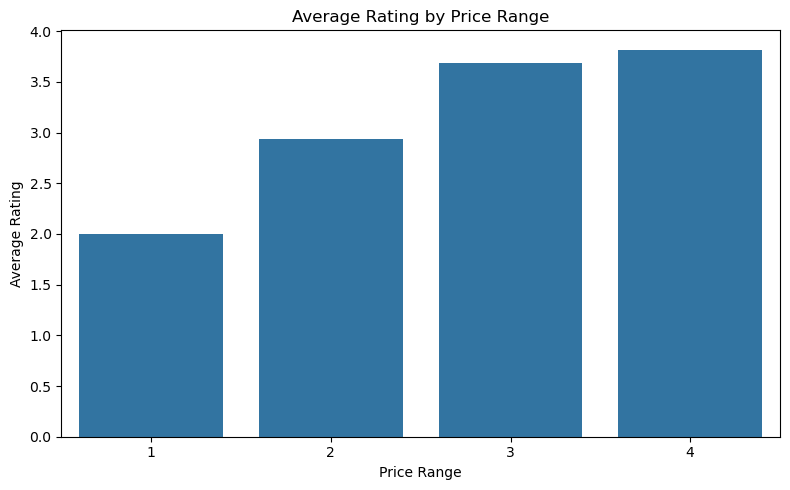

In [62]:
#Price range vs rating
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Price range",
    y="Aggregate rating",
    errorbar=None
)

plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

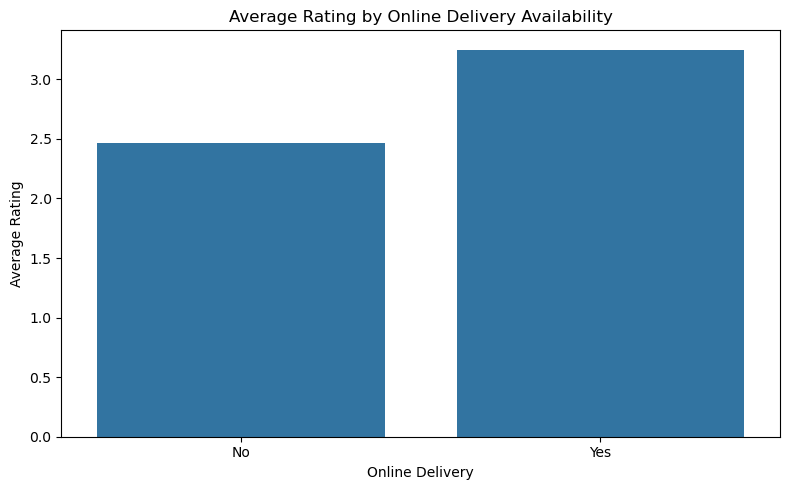

In [64]:
#Online delivery vs rating
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Has Online delivery",
    y="Aggregate rating",
    errorbar=None
)

plt.title("Average Rating by Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

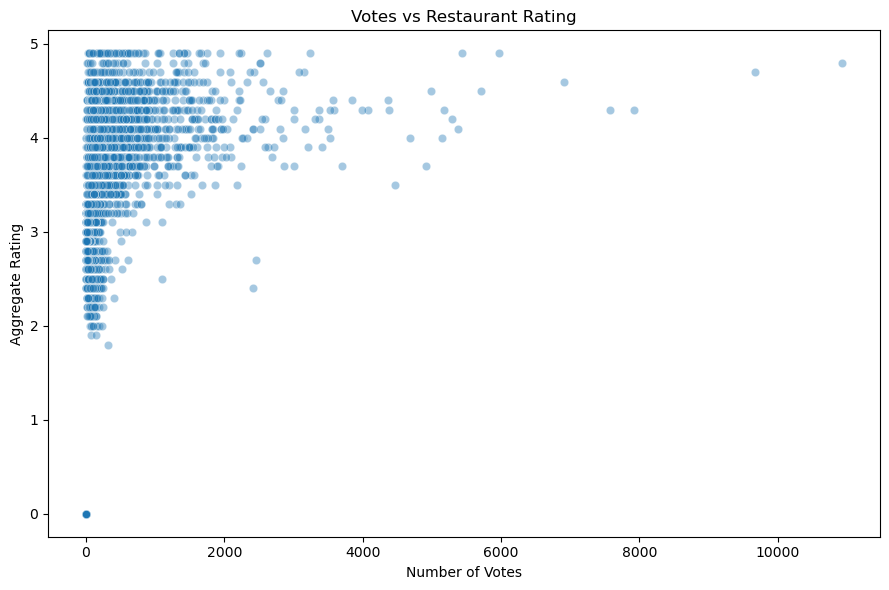

In [66]:
#Votes vs rating
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="Votes",
    y="Aggregate rating",
    alpha=0.4
)

plt.title("Votes vs Restaurant Rating")
plt.xlabel("Number of Votes")
plt.ylabel("Aggregate Rating")
plt.tight_layout()
plt.show()

In [70]:
print(df_clean.shape)

(9551, 25)


In [72]:
import mysql.connector
import pandas as pd

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Umahitha@06",
    database="zomato_project"
)

cursor = connection.cursor()

print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [74]:
cursor.execute("SHOW TABLES;")

for table in cursor.fetchall():
    print(table[0])

dim_cuisine
dim_location
dim_price
dim_rating
fact_restaurant
zomato


In [76]:
tables = [
    "dim_location",
    "dim_cuisine",
    "dim_price",
    "dim_rating",
    "fact_restaurant"
]

for table in tables:
    cursor.execute(f"SELECT COUNT(*) FROM {table};")
    count = cursor.fetchone()[0]
    print(f"{table}: {count} rows")

dim_location: 0 rows
dim_cuisine: 0 rows
dim_price: 0 rows
dim_rating: 0 rows
fact_restaurant: 0 rows


In [78]:
# Load Location dimension

locations = df_clean[
    ["Country Code", "City", "Address", "Locality", "Locality Verbose",
     "Longitude", "Latitude"]
].drop_duplicates()

print("Unique locations:", len(locations))
locations.head()

Unique locations: 9455


,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude
0,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443
1,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708
2,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404
3,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318
4,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450


In [80]:
locations = df_clean[
    ["Country Code", "City", "Address", "Locality",
     "Locality Verbose", "Longitude", "Latitude"]
].drop_duplicates()

In [84]:
cursor.execute("DESCRIBE dim_location;")

for row in cursor.fetchall():
    print(row)

('location_id', 'int', 'NO', 'PRI', None, 'auto_increment')
('city', 'varchar(100)', 'YES', '', None, '')
('locality', 'varchar(150)', 'YES', '', None, '')
('locality_verbose', 'varchar(200)', 'YES', '', None, '')
('longitude', 'decimal(10,6)', 'YES', '', None, '')
('latitude', 'decimal(10,6)', 'YES', '', None, '')
('country_code', 'int', 'YES', '', None, '')


In [86]:
# Insert locations into dim_location

location_insert = """
INSERT INTO dim_location
(city, locality, locality_verbose, longitude, latitude, country_code)
VALUES (%s, %s, %s, %s, %s, %s)
"""

location_data = locations[
    ["City", "Locality", "Locality Verbose",
     "Longitude", "Latitude", "Country Code"]
].where(pd.notnull(locations), None).values.tolist()

cursor.executemany(location_insert, location_data)
connection.commit()

print("Locations inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Locations inserted successfully!
Rows inserted: 9455


In [88]:
# Prepare cuisine dimension

cuisines = (
    df_clean["Cuisines"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .drop_duplicates()
)

print("Unique cuisines:", len(cuisines))
cuisines.head(10)

Unique cuisines: 146


0      French
0    Japanese
0    Desserts
2     Seafood
2       Asian
2    Filipino
2      Indian
3       Sushi
4      Korean
5     Chinese
Name: Cuisines, dtype: object

In [90]:
cursor.execute("DESCRIBE dim_cuisine;")

for row in cursor.fetchall():
    print(row)

('cuisine_id', 'int', 'NO', 'PRI', None, 'auto_increment')
('cuisine_name', 'varchar(150)', 'YES', 'UNI', None, '')


In [92]:
# Insert cuisines into dim_cuisine

cuisine_insert = """
INSERT IGNORE INTO dim_cuisine (cuisine_name)
VALUES (%s)
"""

cuisine_data = [(c,) for c in cuisines.tolist()]

cursor.executemany(cuisine_insert, cuisine_data)
connection.commit()

print("Cuisines inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Cuisines inserted successfully!
Rows inserted: 146


In [94]:
cursor.execute("DESCRIBE dim_price;")

for row in cursor.fetchall():
    print(row)

('price_id', 'int', 'NO', 'PRI', None, '')
('price_range', 'int', 'YES', '', None, '')


In [96]:
# Prepare price dimension

prices = (
    df_clean["Price range"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print("Unique price ranges:", len(prices))
print(prices.tolist())

Unique price ranges: 4
[1, 2, 3, 4]


In [98]:
# Insert price ranges into dim_price

price_insert = """
INSERT IGNORE INTO dim_price (price_range)
VALUES (%s)
"""

price_data = [(int(p),) for p in prices.tolist()]

cursor.executemany(price_insert, price_data)
connection.commit()

print("Price ranges inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Price ranges inserted successfully!
Rows inserted: 1


In [100]:
cursor.execute("SELECT * FROM dim_price;")

for row in cursor.fetchall():
    print(row)

(0, 1)


In [102]:
cursor.execute("SELECT * FROM dim_price;")

for row in cursor.fetchall():
    print(row)

(0, 1)


In [104]:
cursor.execute("DESCRIBE dim_price;")

for row in cursor.fetchall():
    print(row)

('price_id', 'int', 'NO', 'PRI', None, '')
('price_range', 'int', 'YES', '', None, '')


In [108]:
cursor.execute("DELETE FROM dim_price")
connection.commit()

print("dim_price cleared")

dim_price cleared


In [110]:
price_insert = """
INSERT INTO dim_price (price_id, price_range)
VALUES (%s, %s)
"""

price_data = [
    (1, 1),
    (2, 2),
    (3, 3),
    (4, 4)
]

cursor.executemany(price_insert, price_data)
connection.commit()

print("Price ranges inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Price ranges inserted successfully!
Rows inserted: 4


In [114]:
# Prepare rating dimension

ratings = (
    df_clean["Aggregate rating"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print("Unique ratings:", len(ratings))
print(ratings.tolist())

Unique ratings: 33
[0.0, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9]


In [116]:
# Check dim_rating structure

cursor.execute("DESCRIBE dim_rating;")

for row in cursor.fetchall():
    print(row)

('rating_id', 'int', 'NO', 'PRI', None, 'auto_increment')
('aggregate_rating', 'decimal(3,1)', 'YES', '', None, '')
('rating_text', 'varchar(50)', 'YES', '', None, '')
('rating_color', 'varchar(50)', 'YES', '', None, '')


In [118]:
# Insert ratings into dim_rating

rating_insert = """
INSERT IGNORE INTO dim_rating
(aggregate_rating, rating_text, rating_color)
VALUES (%s, %s, %s)
"""

# Get unique rating information from the original cleaned dataset
rating_data = (
    df_clean[["Aggregate rating", "Rating text", "Rating color"]]
    .dropna(subset=["Aggregate rating"])
    .drop_duplicates()
)

rating_data = [
    (
        float(row["Aggregate rating"]),
        row["Rating text"],
        row["Rating color"]
    )
    for _, row in rating_data.iterrows()
]

cursor.executemany(rating_insert, rating_data)
connection.commit()

print("Ratings inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Ratings inserted successfully!
Rows inserted: 33


In [120]:
cursor.execute("""
SELECT rating_id, aggregate_rating, rating_text, rating_color
FROM dim_rating
ORDER BY aggregate_rating
""")

for row in cursor.fetchall():
    print(row)

(15, Decimal('0.0'), 'Not rated', 'White')
(30, Decimal('1.8'), 'Poor', 'Red')
(33, Decimal('1.9'), 'Poor', 'Red')
(31, Decimal('2.0'), 'Poor', 'Red')
(27, Decimal('2.1'), 'Poor', 'Red')
(22, Decimal('2.2'), 'Poor', 'Red')
(32, Decimal('2.3'), 'Poor', 'Red')
(24, Decimal('2.4'), 'Poor', 'Red')
(29, Decimal('2.5'), 'Average', 'Orange')
(25, Decimal('2.6'), 'Average', 'Orange')
(28, Decimal('2.7'), 'Average', 'Orange')
(26, Decimal('2.8'), 'Average', 'Orange')
(23, Decimal('2.9'), 'Average', 'Orange')
(10, Decimal('3.0'), 'Average', 'Orange')
(14, Decimal('3.1'), 'Average', 'Orange')
(13, Decimal('3.2'), 'Average', 'Orange')
(17, Decimal('3.3'), 'Average', 'Orange')
(20, Decimal('3.4'), 'Average', 'Orange')
(21, Decimal('3.5'), 'Good', 'Yellow')
(8, Decimal('3.6'), 'Good', 'Yellow')
(12, Decimal('3.7'), 'Good', 'Yellow')
(11, Decimal('3.8'), 'Good', 'Yellow')
(19, Decimal('3.9'), 'Good', 'Yellow')
(5, Decimal('4.0'), 'Very Good', 'Green')
(16, Decimal('4.1'), 'Very Good', 'Green')
(6, De

In [122]:
cursor.execute("DESCRIBE fact_restaurant;")

for row in cursor.fetchall():
    print(row)

('restaurant_id', 'bigint', 'NO', 'PRI', None, '')
('restaurant_name', 'varchar(255)', 'YES', '', None, '')
('location_id', 'int', 'YES', 'MUL', None, '')
('cuisine_id', 'int', 'YES', 'MUL', None, '')
('price_id', 'int', 'YES', 'MUL', None, '')
('rating_id', 'int', 'YES', 'MUL', None, '')
('average_cost_for_two', 'decimal(12,2)', 'YES', '', None, '')
('votes', 'int', 'YES', '', None, '')
('has_table_booking', 'tinyint(1)', 'YES', '', None, '')
('has_online_delivery', 'tinyint(1)', 'YES', '', None, '')
('is_delivering_now', 'tinyint(1)', 'YES', '', None, '')


In [124]:
cursor.execute("""
SELECT
    COLUMN_NAME,
    REFERENCED_TABLE_NAME,
    REFERENCED_COLUMN_NAME
FROM INFORMATION_SCHEMA.KEY_COLUMN_USAGE
WHERE TABLE_SCHEMA = 'zomato_project'
  AND TABLE_NAME = 'fact_restaurant'
  AND REFERENCED_TABLE_NAME IS NOT NULL;
""")

for row in cursor.fetchall():
    print(row)

('location_id', 'dim_location', 'location_id')
('cuisine_id', 'dim_cuisine', 'cuisine_id')
('price_id', 'dim_price', 'price_id')
('rating_id', 'dim_rating', 'rating_id')


In [126]:
# Prepare restaurant fact data

restaurant_data = df_clean[
    [
        "Restaurant ID",
        "Restaurant Name",
        "City",
        "Cuisines",
        "Price range",
        "Aggregate rating",
        "Votes",
        "Has Table booking",
        "Has Online delivery",
        "Is delivering now"
    ]
].copy()

restaurant_data.head()

,Restaurant ID,Restaurant Name,City,Cuisines,Price range,Aggregate rating,Votes,Has Table booking,Has Online delivery,Is delivering now
0,6317637,Le Petit Souffle,Makati City,"French, Japanese, Desserts",3,4.8,314,Yes,No,No
1,6304287,Izakaya Kikufuji,Makati City,Japanese,3,4.5,591,Yes,No,No
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",4,4.4,270,Yes,No,No
3,6318506,Ooma,Mandaluyong City,"Japanese, Sushi",4,4.9,365,No,No,No
4,6314302,Sambo Kojin,Mandaluyong City,"Japanese, Korean",4,4.8,229,Yes,No,No


In [128]:
# Create lookup dictionaries from MySQL dimension tables

# Location mapping
cursor.execute("""
SELECT location_id, city
FROM dim_location
""")
location_map = {city: location_id for location_id, city in cursor.fetchall()}

# Cuisine mapping
cursor.execute("""
SELECT cuisine_id, cuisine_name
FROM dim_cuisine
""")
cuisine_map = {cuisine_name: cuisine_id for cuisine_id, cuisine_name in cursor.fetchall()}

# Price mapping
cursor.execute("""
SELECT price_id, price_range
FROM dim_price
""")
price_map = {price_range: price_id for price_id, price_range in cursor.fetchall()}

# Rating mapping
cursor.execute("""
SELECT rating_id, aggregate_rating
FROM dim_rating
""")
rating_map = {
    float(aggregate_rating): rating_id
    for rating_id, aggregate_rating in cursor.fetchall()
}

print("Location mappings:", len(location_map))
print("Cuisine mappings:", len(cuisine_map))
print("Price mappings:", len(price_map))
print("Rating mappings:", len(rating_map))

Location mappings: 141
Cuisine mappings: 146
Price mappings: 4
Rating mappings: 33


In [130]:
# Map restaurant data to dimension IDs

restaurant_insert_data = []

for _, row in restaurant_data.iterrows():

    # Location ID
    location_id = location_map.get(row["City"])

    # Use the first cuisine when multiple cuisines are listed
    first_cuisine = str(row["Cuisines"]).split(",")[0].strip()
    cuisine_id = cuisine_map.get(first_cuisine)

    # Price ID
    price_id = price_map.get(int(row["Price range"]))

    # Rating ID
    rating_id = rating_map.get(float(row["Aggregate rating"]))

    # Skip rows where required dimension IDs are missing
    if location_id is None or cuisine_id is None or price_id is None or rating_id is None:
        continue

    restaurant_insert_data.append((
        int(row["Restaurant ID"]),
        str(row["Restaurant Name"]),
        location_id,
        cuisine_id,
        price_id,
        rating_id,
        float(row["Aggregate rating"]),
        int(row["Votes"]),
        1 if row["Has Table booking"] == "Yes" else 0,
        1 if row["Has Online delivery"] == "Yes" else 0,
        1 if row["Is delivering now"] == "Yes" else 0
    ))

print("Rows ready for insertion:", len(restaurant_insert_data))
print(restaurant_insert_data[:3])

Rows ready for insertion: 9551
[(6317637, 'Le Petit Souffle', 2, 1, 3, 1, 4.8, 314, 1, 0, 0), (6304287, 'Izakaya Kikufuji', 2, 2, 3, 2, 4.5, 591, 1, 0, 0), (6300002, 'Heat - Edsa Shangri-La', 6, 4, 4, 3, 4.4, 270, 1, 0, 0)]


In [134]:
cursor.execute("DESCRIBE fact_restaurant;")

for row in cursor.fetchall():
    print(row)

('restaurant_id', 'bigint', 'NO', 'PRI', None, '')
('restaurant_name', 'varchar(255)', 'YES', '', None, '')
('location_id', 'int', 'YES', 'MUL', None, '')
('cuisine_id', 'int', 'YES', 'MUL', None, '')
('price_id', 'int', 'YES', 'MUL', None, '')
('rating_id', 'int', 'YES', 'MUL', None, '')
('average_cost_for_two', 'decimal(12,2)', 'YES', '', None, '')
('votes', 'int', 'YES', '', None, '')
('has_table_booking', 'tinyint(1)', 'YES', '', None, '')
('has_online_delivery', 'tinyint(1)', 'YES', '', None, '')
('is_delivering_now', 'tinyint(1)', 'YES', '', None, '')


In [136]:
# Rebuild restaurant data with average cost for two

restaurant_data = df_clean[
    [
        "Restaurant ID",
        "Restaurant Name",
        "City",
        "Cuisines",
        "Price range",
        "Aggregate rating",
        "Average Cost for two",
        "Votes",
        "Has Table booking",
        "Has Online delivery",
        "Is delivering now"
    ]
].copy()

restaurant_data.head()

,Restaurant ID,Restaurant Name,City,Cuisines,Price range,Aggregate rating,Average Cost for two,Votes,Has Table booking,Has Online delivery,Is delivering now
0,6317637,Le Petit Souffle,Makati City,"French, Japanese, Desserts",3,4.8,1100,314,Yes,No,No
1,6304287,Izakaya Kikufuji,Makati City,Japanese,3,4.5,1200,591,Yes,No,No
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",4,4.4,4000,270,Yes,No,No
3,6318506,Ooma,Mandaluyong City,"Japanese, Sushi",4,4.9,1500,365,No,No,No
4,6314302,Sambo Kojin,Mandaluyong City,"Japanese, Korean",4,4.8,1500,229,Yes,No,No


In [138]:
# Prepare data for fact_restaurant

restaurant_insert_data = []

for _, row in restaurant_data.iterrows():

    location_id = location_map.get(row["City"])

    # Use first cuisine when multiple cuisines exist
    first_cuisine = str(row["Cuisines"]).split(",")[0].strip()
    cuisine_id = cuisine_map.get(first_cuisine)

    price_id = price_map.get(int(row["Price range"]))

    rating_id = rating_map.get(float(row["Aggregate rating"]))

    if location_id is None or cuisine_id is None or price_id is None or rating_id is None:
        continue

    restaurant_insert_data.append((
        int(row["Restaurant ID"]),
        str(row["Restaurant Name"]),
        location_id,
        cuisine_id,
        price_id,
        rating_id,
        float(row["Average Cost for two"]),
        int(row["Votes"]),
        1 if row["Has Table booking"] == "Yes" else 0,
        1 if row["Has Online delivery"] == "Yes" else 0,
        1 if row["Is delivering now"] == "Yes" else 0
    ))

print("Rows ready for insertion:", len(restaurant_insert_data))
print(restaurant_insert_data[:3])

Rows ready for insertion: 9551
[(6317637, 'Le Petit Souffle', 2, 1, 3, 1, 1100.0, 314, 1, 0, 0), (6304287, 'Izakaya Kikufuji', 2, 2, 3, 2, 1200.0, 591, 1, 0, 0), (6300002, 'Heat - Edsa Shangri-La', 6, 4, 4, 3, 4000.0, 270, 1, 0, 0)]


In [140]:
# Insert restaurant data into fact_restaurant

restaurant_insert = """
INSERT INTO fact_restaurant
(
    restaurant_id,
    restaurant_name,
    location_id,
    cuisine_id,
    price_id,
    rating_id,
    average_cost_for_two,
    votes,
    has_table_booking,
    has_online_delivery,
    is_delivering_now
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

cursor.executemany(restaurant_insert, restaurant_insert_data)
connection.commit()

print("Restaurant data inserted successfully!")
print("Rows inserted:", cursor.rowcount)

Restaurant data inserted successfully!
Rows inserted: 9551


In [142]:
# Verify fact_restaurant

cursor.execute("SELECT COUNT(*) FROM fact_restaurant;")
print("Total restaurants in fact_restaurant:", cursor.fetchone()[0])

cursor.execute("""
SELECT *
FROM fact_restaurant
LIMIT 5;
""")

for row in cursor.fetchall():
    print(row)

Total restaurants in fact_restaurant: 9551
(53, 'Amber', 7954, 83, 3, 25, Decimal('1800.00'), 152, 1, 1, 0)
(55, "Berco's", 7954, 10, 3, 19, Decimal('1100.00'), 2639, 1, 1, 0)
(60, "Colonel's Kababz", 7954, 83, 2, 13, Decimal('900.00'), 600, 1, 0, 0)
(64, 'Diva - The Italian Restaurant', 7954, 16, 4, 11, Decimal('2500.00'), 372, 1, 1, 0)
(65, 'Drums of Heaven', 7954, 10, 3, 21, Decimal('1800.00'), 234, 1, 1, 0)


In [144]:
# Check for NULL values in fact_restaurant

cursor.execute("""
SELECT
    COUNT(*) AS total_rows,
    SUM(restaurant_id IS NULL) AS null_restaurant_id,
    SUM(restaurant_name IS NULL) AS null_restaurant_name,
    SUM(location_id IS NULL) AS null_location_id,
    SUM(cuisine_id IS NULL) AS null_cuisine_id,
    SUM(price_id IS NULL) AS null_price_id,
    SUM(rating_id IS NULL) AS null_rating_id,
    SUM(average_cost_for_two IS NULL) AS null_average_cost,
    SUM(votes IS NULL) AS null_votes
FROM fact_restaurant;
""")

result = cursor.fetchone()

print("Data quality check:")
print("Total rows:", result[0])
print("NULL restaurant_id:", result[1])
print("NULL restaurant_name:", result[2])
print("NULL location_id:", result[3])
print("NULL cuisine_id:", result[4])
print("NULL price_id:", result[5])
print("NULL rating_id:", result[6])
print("NULL average_cost_for_two:", result[7])
print("NULL votes:", result[8])

Data quality check:
Total rows: 9551
NULL restaurant_id: 0
NULL restaurant_name: 0
NULL location_id: 0
NULL cuisine_id: 0
NULL price_id: 0
NULL rating_id: 0
NULL average_cost_for_two: 0
NULL votes: 0


In [146]:
# 1. Restaurant count by city

cursor.execute("""
SELECT
    l.city,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
GROUP BY l.city
ORDER BY restaurant_count DESC;
""")

for row in cursor.fetchall():
    print(row)

('New Delhi', 5473)
('Gurgaon', 1118)
('Noida', 1080)
('Faridabad', 251)
('Ghaziabad', 25)
('Ahmedabad', 21)
('Amritsar', 21)
('Bhubaneshwar', 21)
('Guwahati', 21)
('Lucknow', 21)
('Brasí_lia', 20)
('Rio de Janeiro', 20)
('Sí£o Paulo', 20)
('Albany', 20)
('Athens', 20)
('Augusta', 20)
('Boise', 20)
('Cedar Rapids/Iowa City', 20)
('Columbus', 20)
('Dalton', 20)
('Davenport', 20)
('Des Moines', 20)
('Dubuque', 20)
('Gainesville', 20)
('Macon', 20)
('Orlando', 20)
('Pensacola', 20)
('Pocatello', 20)
('Rest of Hawaii', 20)
('Savannah', 20)
('Singapore', 20)
('Sioux City', 20)
('Tampa Bay', 20)
('Valdosta', 20)
('Waterloo', 20)
('Abu Dhabi', 20)
('Dubai', 20)
('Sharjah', 20)
('Agra', 20)
('Allahabad', 20)
('Aurangabad', 20)
('Bangalore', 20)
('Bhopal', 20)
('Chennai', 20)
('Coimbatore', 20)
('Dehradun', 20)
('Goa', 20)
('Indore', 20)
('Jaipur', 20)
('Kanpur', 20)
('Kochi', 20)
('Kolkata', 20)
('Ludhiana', 20)
('Mangalore', 20)
('Mumbai', 20)
('Mysore', 20)
('Nagpur', 20)
('Nashik', 20)
('Pa

In [148]:
# Top 10 cities by restaurant count

cursor.execute("""
SELECT
    l.city,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
GROUP BY l.city
ORDER BY restaurant_count DESC
LIMIT 10;
""")

print("Top 10 cities by number of restaurants:\n")

for row in cursor.fetchall():
    print(row)

Top 10 cities by number of restaurants:

('New Delhi', 5473)
('Gurgaon', 1118)
('Noida', 1080)
('Faridabad', 251)
('Ghaziabad', 25)
('Amritsar', 21)
('Bhubaneshwar', 21)
('Ahmedabad', 21)
('Guwahati', 21)
('Lucknow', 21)


In [150]:
# 2. Restaurant count by rating

cursor.execute("""
SELECT
    r.rating_text,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY r.rating_text
ORDER BY restaurant_count DESC;
""")

for row in cursor.fetchall():
    print(row)

('Average', 3737)
('Not rated', 2148)
('Good', 2100)
('Very Good', 1079)
('Excellent', 301)
('Poor', 186)


In [152]:
# 3. Average rating and total votes by city

cursor.execute("""
SELECT
    l.city,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    SUM(f.votes) AS total_votes
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY l.city
ORDER BY average_rating DESC;
""")

for row in cursor.fetchall():
    print(row)

('Inner City', 2, Decimal('4.90'), Decimal('635'))
('Quezon City', 1, Decimal('4.80'), Decimal('294'))
('Makati City', 2, Decimal('4.65'), Decimal('905'))
('Mandaluyong City', 4, Decimal('4.63'), Decimal('1200'))
('Pasig City', 3, Decimal('4.63'), Decimal('2090'))
('Beechworth', 1, Decimal('4.60'), Decimal('237'))
('London', 20, Decimal('4.54'), Decimal('8724'))
('Taguig City', 4, Decimal('4.53'), Decimal('1663'))
('Tagaytay City', 1, Decimal('4.50'), Decimal('211'))
('Lincoln', 1, Decimal('4.50'), Decimal('799'))
('Secunderabad', 2, Decimal('4.50'), Decimal('1902'))
('Orlando', 20, Decimal('4.48'), Decimal('23989'))
('Tampa Bay', 20, Decimal('4.41'), Decimal('27407'))
('Rest of Hawaii', 20, Decimal('4.41'), Decimal('15055'))
('Tanunda', 1, Decimal('4.40'), Decimal('339'))
('Palm Cove', 1, Decimal('4.40'), Decimal('381'))
('Bangalore', 20, Decimal('4.38'), Decimal('56115'))
('Dubai', 20, Decimal('4.37'), Decimal('18693'))
('Pasay City', 3, Decimal('4.37'), Decimal('1818'))
('Jakarta', 

In [154]:
# 4. Top 10 restaurants by votes

cursor.execute("""
SELECT
    restaurant_name,
    votes,
    average_cost_for_two
FROM fact_restaurant
ORDER BY votes DESC
LIMIT 10;
""")

print("Top 10 most-voted restaurants:\n")

for row in cursor.fetchall():
    print(row)

Top 10 most-voted restaurants:

('Toit', 10934, Decimal('2000.00'))
('Truffles', 9667, Decimal('800.00'))
('Hauz Khas Social', 7931, Decimal('1600.00'))
('Peter Cat', 7574, Decimal('1000.00'))
("AB's - Absolute Barbecues", 6907, Decimal('1400.00'))
('Barbeque Nation', 5966, Decimal('1600.00'))
('Big Brewsky', 5705, Decimal('1800.00'))
("AB's - Absolute Barbecues", 5434, Decimal('1500.00'))
('The Black Pearl', 5385, Decimal('1400.00'))
('BarBQ', 5288, Decimal('900.00'))


In [156]:
# 5. Most common cuisines

cursor.execute("""
SELECT
    c.cuisine_name,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
GROUP BY c.cuisine_name
ORDER BY restaurant_count DESC
LIMIT 15;
""")

print("Top 15 cuisines by restaurant count:\n")

for row in cursor.fetchall():
    print(row)

Top 15 cuisines by restaurant count:

('North Indian', 2992)
('Chinese', 855)
('Fast Food', 672)
('Bakery', 621)
('Cafe', 617)
('American', 278)
('South Indian', 262)
('Mithai', 246)
('Street Food', 236)
('Continental', 235)
('Italian', 234)
('Pizza', 232)
('Mughlai', 215)
('Ice Cream', 178)
('Desserts', 150)


In [158]:
# 6. Cuisine performance by rating

cursor.execute("""
SELECT
    c.cuisine_name,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    SUM(f.votes) AS total_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY c.cuisine_name
HAVING COUNT(*) >= 10
ORDER BY average_rating DESC;
""")

for row in cursor.fetchall():
    print(row)

('Kebab', 10, Decimal('4.38'), Decimal('1536'))
('Modern Indian', 14, Decimal('4.31'), Decimal('14350'))
('International', 13, Decimal('4.29'), Decimal('6487'))
('French', 14, Decimal('4.18'), Decimal('2464'))
('British', 12, Decimal('4.17'), Decimal('3051'))
('BBQ', 18, Decimal('4.12'), Decimal('6172'))
('Steak', 13, Decimal('4.11'), Decimal('2569'))
('Indian', 51, Decimal('4.10'), Decimal('17376'))
('Seafood', 49, Decimal('3.97'), Decimal('19742'))
('Thai', 29, Decimal('3.96'), Decimal('5262'))
('Sushi', 13, Decimal('3.94'), Decimal('1621'))
('Breakfast', 24, Decimal('3.93'), Decimal('10490'))
('European', 62, Decimal('3.89'), Decimal('45842'))
('Goan', 10, Decimal('3.87'), Decimal('4497'))
('Mediterranean', 28, Decimal('3.84'), Decimal('15511'))
('Japanese', 72, Decimal('3.77'), Decimal('15622'))
('Mexican', 62, Decimal('3.73'), Decimal('22085'))
('Asian', 77, Decimal('3.68'), Decimal('26240'))
('Continental', 235, Decimal('3.61'), Decimal('94569'))
('Brazilian', 22, Decimal('3.59')

In [160]:
# 7. Cuisine by price range

cursor.execute("""
SELECT
    c.cuisine_name,
    p.price_range,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_price p
    ON f.price_id = p.price_id
GROUP BY c.cuisine_name, p.price_range
ORDER BY c.cuisine_name, p.price_range;
""")

for row in cursor.fetchall():
    print(row)

('Afghani', 1, 1)
('Afghani', 2, 6)
('African', 4, 2)
('American', 1, 25)
('American', 2, 148)
('American', 3, 67)
('American', 4, 38)
('Andhra', 1, 1)
('Andhra', 2, 2)
('Arabian', 1, 1)
('Arabian', 2, 2)
('Arabian', 3, 2)
('Argentine', 4, 1)
('Asian', 1, 13)
('Asian', 2, 24)
('Asian', 3, 26)
('Asian', 4, 14)
('Asian Fusion', 4, 2)
('Assamese', 1, 2)
('Assamese', 2, 1)
('Australian', 2, 1)
('Awadhi', 1, 2)
('Awadhi', 2, 3)
('Bakery', 1, 463)
('Bakery', 2, 144)
('Bakery', 3, 13)
('Bakery', 4, 1)
('Bar Food', 1, 1)
('Bar Food', 2, 4)
('Bar Food', 3, 3)
('Bar Food', 4, 1)
('BBQ', 1, 6)
('BBQ', 2, 10)
('BBQ', 3, 1)
('BBQ', 4, 1)
('Bengali', 1, 4)
('Bengali', 2, 10)
('Bengali', 3, 4)
('Beverages', 1, 76)
('Beverages', 2, 1)
('Beverages', 3, 1)
('Beverages', 4, 1)
('Bihari', 1, 2)
('Bihari', 2, 1)
('Bihari', 3, 1)
('Biryani', 1, 57)
('Biryani', 2, 49)
('Biryani', 3, 6)
('Brazilian', 1, 1)
('Brazilian', 2, 3)
('Brazilian', 3, 9)
('Brazilian', 4, 9)
('Breakfast', 1, 11)
('Breakfast', 2, 9)
('B

In [162]:
# 8. Restaurants by price range

cursor.execute("""
SELECT
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(f.average_cost_for_two), 2) AS avg_cost_for_two
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
GROUP BY p.price_range
ORDER BY p.price_range;
""")

print("Restaurants by price range:\n")

for row in cursor.fetchall():
    print(row)

Restaurants by price range:

(1, 4444, Decimal('275.18'))
(2, 3113, Decimal('596.83'))
(3, 1408, Decimal('5177.27'))
(4, 586, Decimal('1848.52'))


In [164]:
# 9. Rating performance by price range

cursor.execute("""
SELECT
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    SUM(f.votes) AS total_votes
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY p.price_range
ORDER BY p.price_range;
""")

for row in cursor.fetchall():
    print(row)

(1, 4444, Decimal('2.00'), Decimal('198191'))
(2, 3113, Decimal('2.94'), Decimal('459501'))
(3, 1408, Decimal('3.68'), Decimal('624956'))
(4, 586, Decimal('3.82'), Decimal('215997'))


In [166]:
# 10. Online delivery and table booking analysis

cursor.execute("""
SELECT
    has_table_booking,
    has_online_delivery,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(average_cost_for_two), 2) AS avg_cost_for_two,
    ROUND(AVG(votes), 0) AS avg_votes
FROM fact_restaurant
GROUP BY has_table_booking, has_online_delivery
ORDER BY restaurant_count DESC;
""")

print("Restaurant services analysis:\n")

for row in cursor.fetchall():
    print(row)

Restaurant services analysis:

(0, 0, 6377, Decimal('1342.08'), Decimal('122'))
(0, 1, 2016, Decimal('553.91'), Decimal('155'))
(1, 0, 723, Decimal('1703.89'), Decimal('280'))
(1, 1, 435, Decimal('1256.69'), Decimal('474'))


In [168]:
# 11. Online delivery availability

cursor.execute("""
SELECT
    has_online_delivery,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY has_online_delivery;
""")

for row in cursor.fetchall():
    print(row)

(0, 7100, Decimal('2.47'), Decimal('138'))
(1, 2451, Decimal('3.25'), Decimal('211'))


In [170]:
# 12. Highly rated restaurants with meaningful customer engagement

cursor.execute("""
SELECT
    f.restaurant_name,
    l.city,
    c.cuisine_name,
    r.aggregate_rating,
    f.votes,
    p.price_range,
    f.average_cost_for_two
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
JOIN dim_price p
    ON f.price_id = p.price_id
WHERE f.votes >= 100
ORDER BY r.aggregate_rating DESC, f.votes DESC
LIMIT 20;
""")

print("Highly rated restaurants with 100+ votes:\n")

for row in cursor.fetchall():
    print(row)

Highly rated restaurants with 100+ votes:

('Barbeque Nation', 'Kolkata', 'North Indian', Decimal('4.9'), 5966, 3, Decimal('1600.00'))
("AB's - Absolute Barbecues", 'Hyderabad', 'European', Decimal('4.9'), 5434, 3, Decimal('1500.00'))
('Mirchi And Mime', 'Mumbai', 'North Indian', Decimal('4.9'), 3244, 3, Decimal('1500.00'))
('Naturals Ice Cream', 'New Delhi', 'Ice Cream', Decimal('4.9'), 2620, 1, Decimal('150.00'))
("McGuire's Irish Pub & Brewery", 'Pensacola', 'Burger', Decimal('4.9'), 2238, 3, Decimal('40.00'))
('Talaga Sampireun', 'Tangerang', 'Sunda', Decimal('4.9'), 2212, 3, Decimal('200000.00'))
('Indian Accent - The Manor', 'New Delhi', 'Modern Indian', Decimal('4.9'), 1934, 4, Decimal('4000.00'))
('Barbeque Nation', 'Kolkata', 'North Indian', Decimal('4.9'), 1753, 3, Decimal('1600.00'))
('Talaga Sampireun', 'Jakarta', 'Sunda', Decimal('4.9'), 1662, 3, Decimal('200000.00'))
('Talaga Sampireun', 'Jakarta', 'Sunda', Decimal('4.9'), 1640, 3, Decimal('200000.00'))
("Pom Pom's Teahou

In [172]:
# 13. City and cuisine analysis

cursor.execute("""
SELECT
    l.city,
    c.cuisine_name,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    SUM(f.votes) AS total_votes
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY l.city, c.cuisine_name
HAVING COUNT(*) >= 5
ORDER BY restaurant_count DESC
LIMIT 30;
""")

for row in cursor.fetchall():
    print(row)

('New Delhi', 'North Indian', 1848, Decimal('2.34'), Decimal('188687'))
('New Delhi', 'Chinese', 569, Decimal('2.21'), Decimal('45605'))
('New Delhi', 'Fast Food', 446, Decimal('2.30'), Decimal('23634'))
('Noida', 'North Indian', 433, Decimal('2.04'), Decimal('27188'))
('New Delhi', 'Bakery', 397, Decimal('2.30'), Decimal('25197'))
('Gurgaon', 'North Indian', 367, Decimal('2.37'), Decimal('37288'))
('New Delhi', 'Cafe', 298, Decimal('3.12'), Decimal('59597'))
('New Delhi', 'Street Food', 188, Decimal('2.26'), Decimal('14065'))
('New Delhi', 'Mithai', 186, Decimal('1.90'), Decimal('3858'))
('New Delhi', 'South Indian', 184, Decimal('2.36'), Decimal('24423'))
('New Delhi', 'Mughlai', 161, Decimal('1.86'), Decimal('18124'))
('New Delhi', 'Pizza', 135, Decimal('2.36'), Decimal('11701'))
('New Delhi', 'Ice Cream', 119, Decimal('2.81'), Decimal('8746'))
('New Delhi', 'Continental', 112, Decimal('3.49'), Decimal('42825'))
('Faridabad', 'North Indian', 102, Decimal('1.81'), Decimal('2184'))
('

In [174]:
# 14. Relationship between cost and rating

cursor.execute("""
SELECT
    p.price_range,
    ROUND(AVG(f.average_cost_for_two), 2) AS avg_cost,
    ROUND(AVG(r.aggregate_rating), 2) AS avg_rating,
    ROUND(AVG(f.votes), 0) AS avg_votes,
    COUNT(*) AS restaurant_count
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY p.price_range
ORDER BY p.price_range;
""")

for row in cursor.fetchall():
    print(row)

(1, Decimal('275.18'), Decimal('2.00'), Decimal('45'), 4444)
(2, Decimal('596.83'), Decimal('2.94'), Decimal('148'), 3113)
(3, Decimal('5177.27'), Decimal('3.68'), Decimal('444'), 1408)
(4, Decimal('1848.52'), Decimal('3.82'), Decimal('369'), 586)


In [178]:
# 15. Restaurants offering both table booking and online delivery

cursor.execute("""
SELECT
    COUNT(*) AS restaurants_with_both_services,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
WHERE f.has_table_booking = 1
  AND f.has_online_delivery = 1;
""")

result = cursor.fetchone()

print("Restaurants with both table booking and online delivery:", result[0])
print("Average rating:", result[1])
print("Average votes:", result[2])
print("Average cost for two:", result[3])

Restaurants with both table booking and online delivery: 435
Average rating: 3.60
Average votes: 474
Average cost for two: 1256.69


In [180]:
# 16. Restaurants offering online delivery

cursor.execute("""
SELECT
    f.has_online_delivery,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY f.has_online_delivery
ORDER BY f.has_online_delivery;
""")

print("Online delivery analysis:\n")

for row in cursor.fetchall():
    print(row)

Online delivery analysis:

(0, 7100, Decimal('2.47'), Decimal('138'))
(1, 2451, Decimal('3.25'), Decimal('211'))


In [182]:
# 17. Restaurants offering table booking

cursor.execute("""
SELECT
    f.has_table_booking,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY f.has_table_booking
ORDER BY f.has_table_booking;
""")

print("Table booking analysis:\n")

for row in cursor.fetchall():
    print(row)

Table booking analysis:

(0, 8393, Decimal('2.56'), Decimal('130'))
(1, 1158, Decimal('3.44'), Decimal('353'))


In [184]:
# 18. Average rating, votes, and cost by price range

cursor.execute("""
SELECT
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY p.price_range
ORDER BY p.price_range;
""")

print("Analysis by price range:\n")

for row in cursor.fetchall():
    print(row)

Analysis by price range:

(1, 4444, Decimal('2.00'), Decimal('45'), Decimal('275.18'))
(2, 3113, Decimal('2.94'), Decimal('148'), Decimal('596.83'))
(3, 1408, Decimal('3.68'), Decimal('444'), Decimal('5177.27'))
(4, 586, Decimal('3.82'), Decimal('369'), Decimal('1848.52'))


In [186]:
# 19. Restaurant distribution by rating text

cursor.execute("""
SELECT
    r.rating_text,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY r.rating_text
ORDER BY restaurant_count DESC;
""")

print("Restaurant distribution by rating:\n")

for row in cursor.fetchall():
    print(row)

Restaurant distribution by rating:

('Average', 3737, Decimal('48'))
('Not rated', 2148, Decimal('1'))
('Good', 2100, Decimal('229'))
('Very Good', 1079, Decimal('520'))
('Excellent', 301, Decimal('852'))
('Poor', 186, Decimal('91'))


In [188]:
# 20. Average rating by price range

cursor.execute("""
SELECT
    p.price_range,
    r.rating_text,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY
    p.price_range,
    r.rating_text
ORDER BY
    p.price_range,
    average_rating DESC;
""")

print("Rating distribution across price ranges:\n")

for row in cursor.fetchall():
    print(row)

Rating distribution across price ranges:

(1, 'Excellent', 32, Decimal('4.67'), Decimal('710'))
(1, 'Very Good', 144, Decimal('4.16'), Decimal('362'))
(1, 'Good', 608, Decimal('3.66'), Decimal('115'))
(1, 'Average', 1898, Decimal('3.04'), Decimal('26'))
(1, 'Poor', 62, Decimal('2.29'), Decimal('52'))
(1, 'Not rated', 1700, Decimal('0.00'), Decimal('1'))
(2, 'Excellent', 69, Decimal('4.63'), Decimal('759'))
(2, 'Very Good', 325, Decimal('4.16'), Decimal('467'))
(2, 'Good', 794, Decimal('3.67'), Decimal('207'))
(2, 'Average', 1425, Decimal('3.05'), Decimal('58'))
(2, 'Poor', 98, Decimal('2.30'), Decimal('81'))
(2, 'Not rated', 402, Decimal('0.00'), Decimal('1'))
(3, 'Excellent', 126, Decimal('4.65'), Decimal('1043'))
(3, 'Very Good', 416, Decimal('4.17'), Decimal('635'))
(3, 'Good', 498, Decimal('3.72'), Decimal('372'))
(3, 'Average', 313, Decimal('3.10'), Decimal('135'))
(3, 'Poor', 20, Decimal('2.31'), Decimal('111'))
(3, 'Not rated', 35, Decimal('0.00'), Decimal('1'))
(4, 'Excellent',

In [190]:
# 21. Top 10 cities by restaurant count

cursor.execute("""
SELECT
    l.city,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY l.city
ORDER BY restaurant_count DESC
LIMIT 10;
""")

print("Top 10 cities by restaurant count:\n")

for row in cursor.fetchall():
    print(row)

Top 10 cities by restaurant count:

('New Delhi', 5473, Decimal('2.44'), Decimal('115'))
('Gurgaon', 1118, Decimal('2.65'), Decimal('118'))
('Noida', 1080, Decimal('2.04'), Decimal('68'))
('Faridabad', 251, Decimal('1.87'), Decimal('26'))
('Ghaziabad', 25, Decimal('2.85'), Decimal('95'))
('Ahmedabad', 21, Decimal('4.16'), Decimal('584'))
('Bhubaneshwar', 21, Decimal('3.98'), Decimal('202'))
('Lucknow', 21, Decimal('4.20'), Decimal('435'))
('Amritsar', 21, Decimal('3.69'), Decimal('175'))
('Guwahati', 21, Decimal('4.19'), Decimal('236'))


In [192]:
# 22. Top 10 cuisines by restaurant count

cursor.execute("""
SELECT
    c.cuisine_name,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY c.cuisine_name
ORDER BY restaurant_count DESC
LIMIT 10;
""")

print("Top 10 cuisines by restaurant count:\n")

for row in cursor.fetchall():
    print(row)

Top 10 cuisines by restaurant count:

('North Indian', 2992, Decimal('2.40'), Decimal('119'))
('Chinese', 855, Decimal('2.33'), Decimal('99'))
('Fast Food', 672, Decimal('2.35'), Decimal('63'))
('Bakery', 621, Decimal('2.33'), Decimal('68'))
('Cafe', 617, Decimal('3.23'), Decimal('189'))
('American', 278, Decimal('3.56'), Decimal('379'))
('South Indian', 262, Decimal('2.51'), Decimal('131'))
('Mithai', 246, Decimal('1.83'), Decimal('23'))
('Street Food', 236, Decimal('2.27'), Decimal('74'))
('Continental', 235, Decimal('3.61'), Decimal('402'))


In [194]:
# 23. Restaurant performance by city

cursor.execute("""
SELECT
    l.city,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY l.city
HAVING COUNT(*) >= 10
ORDER BY average_rating DESC, restaurant_count DESC
LIMIT 15;
""")

print("Top cities by average restaurant rating:\n")

for row in cursor.fetchall():
    print(row)

Top cities by average restaurant rating:

('London', 20, Decimal('4.54'), Decimal('436'))
('Orlando', 20, Decimal('4.48'), Decimal('1199'))
('Rest of Hawaii', 20, Decimal('4.41'), Decimal('753'))
('Tampa Bay', 20, Decimal('4.41'), Decimal('1370'))
('Bangalore', 20, Decimal('4.38'), Decimal('2806'))
('Dubai', 20, Decimal('4.37'), Decimal('935'))
('Jakarta', 16, Decimal('4.36'), Decimal('743'))
('Hyderabad', 18, Decimal('4.34'), Decimal('1341'))
('Chennai', 20, Decimal('4.32'), Decimal('1385'))
('Ankara', 20, Decimal('4.31'), Decimal('131'))
('Abu Dhabi', 20, Decimal('4.30'), Decimal('302'))
('Sandton', 11, Decimal('4.30'), Decimal('492'))
('ÛÁstanbul', 14, Decimal('4.29'), Decimal('860'))
('Auckland', 20, Decimal('4.28'), Decimal('340'))
('Rio de Janeiro', 20, Decimal('4.27'), Decimal('20'))


In [196]:
# 24. Cuisine performance analysis

cursor.execute("""
SELECT
    c.cuisine_name,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY c.cuisine_name
HAVING COUNT(*) >= 10
ORDER BY average_rating DESC, restaurant_count DESC
LIMIT 15;
""")

print("Top cuisines by average restaurant rating:\n")

for row in cursor.fetchall():
    print(row)

Top cuisines by average restaurant rating:

('Kebab', 10, Decimal('4.38'), Decimal('154'))
('Modern Indian', 14, Decimal('4.31'), Decimal('1025'))
('International', 13, Decimal('4.29'), Decimal('499'))
('French', 14, Decimal('4.18'), Decimal('176'))
('British', 12, Decimal('4.17'), Decimal('254'))
('BBQ', 18, Decimal('4.12'), Decimal('343'))
('Steak', 13, Decimal('4.11'), Decimal('198'))
('Indian', 51, Decimal('4.10'), Decimal('341'))
('Seafood', 49, Decimal('3.97'), Decimal('403'))
('Thai', 29, Decimal('3.96'), Decimal('181'))
('Sushi', 13, Decimal('3.94'), Decimal('125'))
('Breakfast', 24, Decimal('3.93'), Decimal('437'))
('European', 62, Decimal('3.89'), Decimal('739'))
('Goan', 10, Decimal('3.87'), Decimal('450'))
('Mediterranean', 28, Decimal('3.84'), Decimal('554'))


In [198]:
# 25. Cuisine distribution by price range

cursor.execute("""
SELECT
    c.cuisine_name,
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY
    c.cuisine_name,
    p.price_range
HAVING COUNT(*) >= 10
ORDER BY
    c.cuisine_name,
    p.price_range;
""")

print("Cuisine distribution across price ranges:\n")

for row in cursor.fetchall():
    print(row)

Cuisine distribution across price ranges:

('American', 1, 25, Decimal('3.54'), Decimal('198'))
('American', 2, 148, Decimal('3.29'), Decimal('265'))
('American', 3, 67, Decimal('3.95'), Decimal('591'))
('American', 4, 38, Decimal('3.91'), Decimal('570'))
('Asian', 1, 13, Decimal('3.93'), Decimal('374'))
('Asian', 2, 24, Decimal('3.01'), Decimal('142'))
('Asian', 3, 26, Decimal('3.98'), Decimal('483'))
('Asian', 4, 14, Decimal('4.01'), Decimal('386'))
('Bakery', 1, 463, Decimal('2.18'), Decimal('52'))
('Bakery', 2, 144, Decimal('2.71'), Decimal('118'))
('Bakery', 3, 13, Decimal('3.47'), Decimal('79'))
('BBQ', 2, 10, Decimal('4.06'), Decimal('446'))
('Bengali', 2, 10, Decimal('3.43'), Decimal('167'))
('Beverages', 1, 76, Decimal('2.47'), Decimal('49'))
('Biryani', 1, 57, Decimal('1.07'), Decimal('11'))
('Biryani', 2, 49, Decimal('3.10'), Decimal('174'))
('Breakfast', 1, 11, Decimal('3.75'), Decimal('281'))
('Burger', 1, 35, Decimal('2.98'), Decimal('136'))
('Burger', 2, 62, Decimal('3.4

In [200]:
# 25. Cuisine distribution by price range

cursor.execute("""
SELECT
    c.cuisine_name,
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY c.cuisine_name, p.price_range
HAVING COUNT(*) >= 10
ORDER BY c.cuisine_name, p.price_range;
""")

print("Cuisine distribution across price ranges:\n")

for row in cursor.fetchall():
    print(row)

Cuisine distribution across price ranges:

('American', 1, 25, Decimal('3.54'), Decimal('198'))
('American', 2, 148, Decimal('3.29'), Decimal('265'))
('American', 3, 67, Decimal('3.95'), Decimal('591'))
('American', 4, 38, Decimal('3.91'), Decimal('570'))
('Asian', 1, 13, Decimal('3.93'), Decimal('374'))
('Asian', 2, 24, Decimal('3.01'), Decimal('142'))
('Asian', 3, 26, Decimal('3.98'), Decimal('483'))
('Asian', 4, 14, Decimal('4.01'), Decimal('386'))
('Bakery', 1, 463, Decimal('2.18'), Decimal('52'))
('Bakery', 2, 144, Decimal('2.71'), Decimal('118'))
('Bakery', 3, 13, Decimal('3.47'), Decimal('79'))
('BBQ', 2, 10, Decimal('4.06'), Decimal('446'))
('Bengali', 2, 10, Decimal('3.43'), Decimal('167'))
('Beverages', 1, 76, Decimal('2.47'), Decimal('49'))
('Biryani', 1, 57, Decimal('1.07'), Decimal('11'))
('Biryani', 2, 49, Decimal('3.10'), Decimal('174'))
('Breakfast', 1, 11, Decimal('3.75'), Decimal('281'))
('Burger', 1, 35, Decimal('2.98'), Decimal('136'))
('Burger', 2, 62, Decimal('3.4

In [202]:
# 26. Cuisine and rating analysis

cursor.execute("""
SELECT
    c.cuisine_name,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    MIN(r.aggregate_rating) AS minimum_rating,
    MAX(r.aggregate_rating) AS maximum_rating,
    ROUND(AVG(f.votes), 0) AS average_votes
FROM fact_restaurant f
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY c.cuisine_name
HAVING COUNT(*) >= 10
ORDER BY average_rating DESC, restaurant_count DESC;
""")

print("Cuisine rating analysis:\n")

for row in cursor.fetchall():
    print(row)

Cuisine rating analysis:

('Kebab', 10, Decimal('4.38'), Decimal('4.2'), Decimal('4.6'), Decimal('154'))
('Modern Indian', 14, Decimal('4.31'), Decimal('3.4'), Decimal('4.9'), Decimal('1025'))
('International', 13, Decimal('4.29'), Decimal('3.7'), Decimal('4.9'), Decimal('499'))
('French', 14, Decimal('4.18'), Decimal('3.4'), Decimal('4.9'), Decimal('176'))
('British', 12, Decimal('4.17'), Decimal('3.8'), Decimal('4.9'), Decimal('254'))
('BBQ', 18, Decimal('4.12'), Decimal('3.3'), Decimal('4.9'), Decimal('343'))
('Steak', 13, Decimal('4.11'), Decimal('3.5'), Decimal('4.9'), Decimal('198'))
('Indian', 51, Decimal('4.10'), Decimal('0.0'), Decimal('4.9'), Decimal('341'))
('Seafood', 49, Decimal('3.97'), Decimal('0.0'), Decimal('4.9'), Decimal('403'))
('Thai', 29, Decimal('3.96'), Decimal('3.0'), Decimal('4.6'), Decimal('181'))
('Sushi', 13, Decimal('3.94'), Decimal('3.5'), Decimal('4.9'), Decimal('125'))
('Breakfast', 24, Decimal('3.93'), Decimal('2.4'), Decimal('4.5'), Decimal('437'))
('

In [204]:
# 27. City and price range analysis

cursor.execute("""
SELECT
    l.city,
    p.price_range,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY l.city, p.price_range
HAVING COUNT(*) >= 10
ORDER BY l.city, p.price_range;
""")

print("City and price range analysis:\n")

for row in cursor.fetchall():
    print(row)

City and price range analysis:

('Abu Dhabi', 4, 10, Decimal('4.47'), Decimal('274.00'))
('Ahmedabad', 3, 11, Decimal('4.13'), Decimal('1040.91'))
('Albany', 1, 11, Decimal('3.55'), Decimal('7.27'))
('Allahabad', 3, 13, Decimal('3.37'), Decimal('584.62'))
('Amritsar', 2, 11, Decimal('3.64'), Decimal('527.27'))
('Ankara', 3, 12, Decimal('4.33'), Decimal('77.50'))
('Athens', 1, 12, Decimal('4.21'), Decimal('10.00'))
('Aurangabad', 2, 15, Decimal('3.34'), Decimal('513.33'))
('Bangalore', 3, 11, Decimal('4.25'), Decimal('1409.09'))
('Bhopal', 2, 14, Decimal('3.91'), Decimal('517.86'))
('Bhubaneshwar', 2, 12, Decimal('3.99'), Decimal('641.67'))
('Brasí_lia', 4, 10, Decimal('3.84'), Decimal('185.00'))
('Coimbatore', 2, 11, Decimal('4.10'), Decimal('513.64'))
('Colombo', 3, 11, Decimal('3.79'), Decimal('2490.91'))
('Dalton', 1, 13, Decimal('4.15'), Decimal('10.00'))
('Davenport', 2, 13, Decimal('3.49'), Decimal('25.00'))
('Dehradun', 3, 12, Decimal('3.96'), Decimal('604.17'))
('Des Moines', 2

In [206]:
# 28. Online delivery by price range

cursor.execute("""
SELECT
    p.price_range,
    f.has_online_delivery,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost
FROM fact_restaurant f
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY
    p.price_range,
    f.has_online_delivery
ORDER BY
    p.price_range,
    f.has_online_delivery;
""")

print("Online delivery by price range:\n")

for row in cursor.fetchall():
    print(row)

Online delivery by price range:

(1, 0, 3743, Decimal('1.81'), Decimal('38'), Decimal('263.88'))
(1, 1, 701, Decimal('3.01'), Decimal('81'), Decimal('335.52'))
(2, 0, 1827, Decimal('2.74'), Decimal('131'), Decimal('570.39'))
(2, 1, 1286, Decimal('3.23'), Decimal('171'), Decimal('634.38'))
(3, 0, 997, Decimal('3.71'), Decimal('423'), Decimal('6791.87'))
(3, 1, 411, Decimal('3.63'), Decimal('496'), Decimal('1260.57'))
(4, 0, 533, Decimal('3.81'), Decimal('335'), Decimal('1855.54'))
(4, 1, 53, Decimal('3.93'), Decimal('705'), Decimal('1777.92'))


In [208]:
# 29. Table booking and rating analysis

cursor.execute("""
SELECT
    f.has_table_booking,
    COUNT(*) AS restaurant_count,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id
GROUP BY f.has_table_booking
ORDER BY f.has_table_booking;
""")

print("Table booking and rating analysis:\n")

for row in cursor.fetchall():
    print(row)

Table booking and rating analysis:

(0, 8393, Decimal('2.56'), Decimal('130'), Decimal('1152.76'))
(1, 1158, Decimal('3.44'), Decimal('353'), Decimal('1535.90'))


In [210]:
# 30. Overall business summary

cursor.execute("""
SELECT
    COUNT(*) AS total_restaurants,
    ROUND(AVG(r.aggregate_rating), 2) AS average_rating,
    ROUND(AVG(f.votes), 0) AS average_votes,
    ROUND(AVG(f.average_cost_for_two), 2) AS average_cost_for_two,
    SUM(f.has_table_booking) AS restaurants_with_table_booking,
    SUM(f.has_online_delivery) AS restaurants_with_online_delivery,
    SUM(f.is_delivering_now) AS restaurants_delivering_now
FROM fact_restaurant f
JOIN dim_rating r
    ON f.rating_id = r.rating_id;
""")

result = cursor.fetchone()

print("OVERALL ZOMATO BUSINESS SUMMARY")
print("--------------------------------")
print("Total restaurants:", result[0])
print("Average rating:", result[1])
print("Average votes:", result[2])
print("Average cost for two:", result[3])
print("Restaurants with table booking:", result[4])
print("Restaurants with online delivery:", result[5])
print("Restaurants delivering now:", result[6])

OVERALL ZOMATO BUSINESS SUMMARY
--------------------------------
Total restaurants: 9551
Average rating: 2.67
Average votes: 157
Average cost for two: 1199.21
Restaurants with table booking: 1158
Restaurants with online delivery: 2451
Restaurants delivering now: 34


In [212]:
# 31A. Restaurant overview dataset

import pandas as pd

query = """
SELECT
    f.restaurant_id,
    f.restaurant_name,
    l.city,
    c.cuisine_name,
    p.price_range,
    r.aggregate_rating,
    r.rating_text,
    f.average_cost_for_two,
    f.votes,
    f.has_table_booking,
    f.has_online_delivery,
    f.is_delivering_now
FROM fact_restaurant f
JOIN dim_location l
    ON f.location_id = l.location_id
JOIN dim_cuisine c
    ON f.cuisine_id = c.cuisine_id
JOIN dim_price p
    ON f.price_id = p.price_id
JOIN dim_rating r
    ON f.rating_id = r.rating_id;
"""

df_powerbi = pd.read_sql(query, connection)

print("Power BI dataset created")
print("Rows:", len(df_powerbi))
print("Columns:", len(df_powerbi.columns))

df_powerbi.head()

Power BI dataset created
Rows: 9551
Columns: 12


/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_6475/3480394391.py:30: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_powerbi = pd.read_sql(query, connection)


,restaurant_id,restaurant_name,city,cuisine_name,price_range,aggregate_rating,rating_text,average_cost_for_two,votes,has_table_booking,has_online_delivery,is_delivering_now
0,349,"34, Chowringhee Lane",New Delhi,Fast Food,1,3.4,Average,350.0,86,0,0,0
1,351,"34, Chowringhee Lane",New Delhi,Fast Food,1,3.5,Good,350.0,345,0,0,0
2,472,Evergreen Sweet House,New Delhi,South Indian,1,3.5,Good,450.0,1198,0,0,0
3,473,Madras Cafe,New Delhi,South Indian,1,2.5,Average,300.0,191,0,0,0
4,584,Nathu's Sweets,New Delhi,North Indian,1,2.1,Poor,400.0,121,0,1,0


In [214]:
# 32. Export dataset for Power BI

output_file = "zomato_powerbi_dataset.csv"

df_powerbi.to_csv(output_file, index=False)

print("File exported successfully:", output_file)
print("Rows exported:", len(df_powerbi))

File exported successfully: zomato_powerbi_dataset.csv
Rows exported: 9551
